# Mini-projet : extraction de caractéristiques d'images
**Dataset : Flowers (tf_flowers)** – 5 classes de fleurs (daisy, dandelion, roses, sunflowers, tulips), photos Flickr, ~218 Mo.
Lien : https://www.tensorflow.org/datasets/catalog/tf_flowers – licence : CC-BY (vérifier la page du dataset).

**Caractéristiques extraites** : couleur (histogramme HSV + moments de couleur) et texture (LBP + GLCM).

In [8]:
# Cellule 1 : imports + téléchargement du dataset
import os, tarfile, urllib.request, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

random.seed(42)
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
if not os.path.exists("flower_photos"):
    urllib.request.urlretrieve(URL, "flower_photos.tgz")
    with tarfile.open("flower_photos.tgz") as t:
        t.extractall(".")
ROOT = "flower_photos"
CLASSES = sorted(d for d in os.listdir(ROOT) if os.path.isdir(os.path.join(ROOT, d)))
N_PER_CLASS = 100
print(CLASSES)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## 1. Choix du sous-ensemble (100 images par classe) et fiche dataset

daisy 633 images au total
dandelion 898 images au total
roses 641 images au total
sunflowers 699 images au total
tulips 799 images au total
Sous-ensemble : 500 images


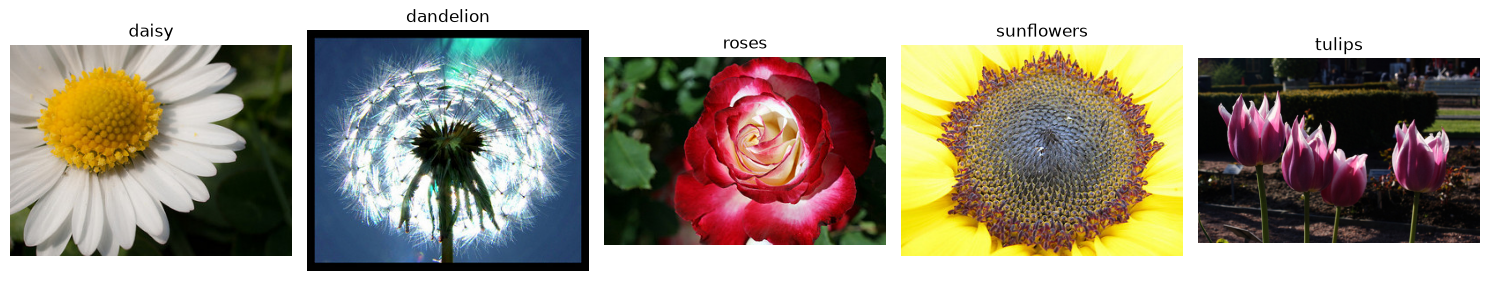

In [9]:
# Cellule 2 : sous-ensemble (100 images/classe) + exemples d'images
files = []
for c in CLASSES:
    imgs = sorted(f for f in os.listdir(os.path.join(ROOT, c)) if f.lower().endswith(".jpg"))
    print(c, len(imgs), "images au total")
    files += [(os.path.join(ROOT, c, f), c) for f in random.sample(imgs, N_PER_CLASS)]
print("Sous-ensemble :", len(files), "images")

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3*len(CLASSES), 3))
for ax, c in zip(axes, CLASSES):
    p = next(p for p, l in files if l == c)
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.savefig("samples.png", dpi=120); plt.show()

## 2. Fonctions d'extraction

In [10]:
# Cellule 3 : fonctions d'extraction (couleur + texture)
SIZE = (128, 128)
LBP_P, LBP_R = 8, 1

def color_features(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    f = {}
    for ch, bins, rng, name in [(0, 8, [0, 180], "H"), (1, 4, [0, 256], "S"), (2, 4, [0, 256], "V")]:
        h = cv2.calcHist([hsv], [ch], None, [bins], rng).flatten()
        h /= h.sum()
        for i, v in enumerate(h): f[f"hist{name}_{i}"] = v
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(float)
    for i, n in enumerate("RGB"):
        f[f"mean{n}"] = rgb[:, i].mean(); f[f"std{n}"] = rgb[:, i].std()
    return f

def texture_features(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    f = {}
    lbp = local_binary_pattern(gray, LBP_P, LBP_R, method="uniform")
    h, _ = np.histogram(lbp, bins=np.arange(0, LBP_P + 3), range=(0, LBP_P + 2))
    h = h / h.sum()
    for i, v in enumerate(h): f[f"lbp_{i}"] = v
    glcm = graycomatrix(gray, distances=[1], angles=[0, np.pi/2], levels=256, symmetric=True, normed=True)
    for prop in ["contrast", "homogeneity", "energy", "correlation"]:
        f[f"glcm_{prop}"] = graycoprops(glcm, prop).mean()
    return f

def extract(path):
    img = cv2.resize(cv2.imread(path), SIZE)
    return {**color_features(img), **texture_features(img)}

## 3. Extraction sur toutes les images et sauvegarde en CSV

In [11]:
# Cellule 4 : extraction sur toutes les images + sauvegarde CSV
rows = []
for path, label in files:
    d = extract(path); d["filename"] = os.path.basename(path); d["label"] = label
    rows.append(d)
df = pd.DataFrame(rows)
df = df[["filename"] + [c for c in df.columns if c not in ("filename", "label")] + ["label"]]
df.to_csv("features.csv", index=False)
print("Taille de la table :", df.shape)
print(df["label"].value_counts())
df.iloc[:5, [0, 1, 2, 3, -6, -5, -4, -1]]

Taille de la table : (500, 38)
label
daisy         100
dandelion     100
roses         100
sunflowers    100
tulips        100
Name: count, dtype: int64


,filename,histH_0,histH_1,histH_2,lbp_9,glcm_contrast,glcm_homogeneity,label
0,15029936576_8d6f96c72c_n.jpg,0.589478,0.213257,0.184570,0.106384,281.389579,0.262843,daisy
1,11023214096_b5b39fab08.jpg,0.563843,0.135864,0.013855,0.078918,280.237635,0.278700,daisy
2,3310644753_5607eb96a4_m.jpg,0.503967,0.244934,0.026428,0.108765,293.752338,0.438031,daisy
3,2632216904_274aa17433.jpg,0.143860,0.538574,0.180115,0.085632,672.971703,0.278150,daisy
4,25360380_1a881a5648.jpg,0.066284,0.197144,0.491638,0.130310,751.187315,0.155968,daisy


# 4 Resultat

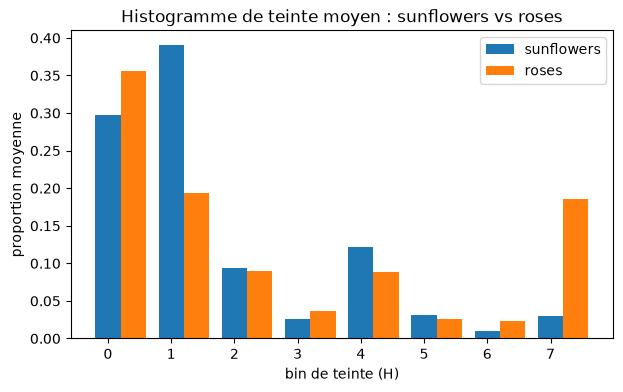

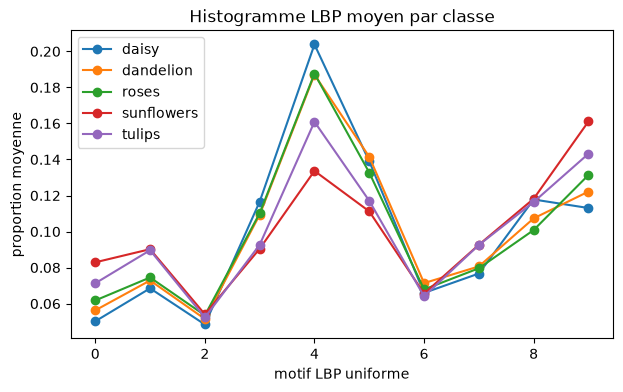

In [12]:
# Cellule 5 : figures (histogramme de teinte + LBP)
hcols = [c for c in df.columns if c.startswith("histH_")]
fig, ax = plt.subplots(figsize=(7, 4))
w = 0.4
for k, c in enumerate(["sunflowers", "roses"]):
    ax.bar(np.arange(len(hcols)) + k*w, df[df.label == c][hcols].mean().values, w, label=c)
ax.set_xlabel("bin de teinte (H)"); ax.set_ylabel("proportion moyenne"); ax.legend()
ax.set_title("Histogramme de teinte moyen : sunflowers vs roses")
plt.savefig("hist_hue.png", dpi=120); plt.show()

lcols = [c for c in df.columns if c.startswith("lbp_")]
fig, ax = plt.subplots(figsize=(7, 4))
for c in CLASSES:
    ax.plot(df[df.label == c][lcols].mean().values, marker="o", label=c)
ax.set_xlabel("motif LBP uniforme"); ax.set_ylabel("proportion moyenne"); ax.legend()
ax.set_title("Histogramme LBP moyen par classe")
plt.savefig("hist_lbp.png", dpi=120); plt.show()

# Cellule 6 : fiche du dataset 

In [16]:
# Cellule 6 : fiche du dataset (PDF 1 page)
from matplotlib.backends.backend_pdf import PdfPages
fig = plt.figure(figsize=(8.27, 11.69))
fig.text(0.08, 0.93, "Fiche du jeu de données", fontsize=18, weight="bold")
info = [
    "Nom : Flowers (tf_flowers / flower_photos)",
    "Lien : https://www.tensorflow.org/datasets/catalog/tf_flowers",
    "Licence : CC-BY (images Flickr) - à vérifier sur la page du dataset",
    f"Classes : {len(CLASSES)} ({', '.join(CLASSES)})",
    f"Images utilisées : {len(files)} ({N_PER_CLASS} par classe, tirage aléatoire, seed=42)",
    "Taille totale : environ 218 Mo",
]
for i, t in enumerate(info):
    fig.text(0.08, 0.88 - i*0.03, t, fontsize=11)
ax = fig.add_axes([0.05, 0.45, 0.9, 0.3]); ax.imshow(plt.imread("samples.png")); ax.axis("off")
with PdfPages("fiche_dataset.pdf") as pdf:
    pdf.savefig(fig)
plt.close(fig)

# Réponses

In [1]:
note = """Courte note - Mini-projet extraction de caractéristiques

Caractéristiques choisies :
- Couleur : histogrammes HSV (8+4+4 bins) et moments de couleur RGB (moyenne, écart-type), car les fleurs se distinguent surtout par leur couleur.
- Texture : histogramme LBP uniforme (P=8, R=1) et propriétés GLCM (contraste, homogénéité, énergie, corrélation), pour décrire l'aspect des pétales et du feuillage.

Difficultés :
- Installer OpenCV dans l'environnement virtuel et télécharger le dataset (environ 218 Mo).
- Choisir le nombre de bins des histogrammes HSV et les paramètres du LBP (P, R).

Questions pour la séance :
1. Comment choisir le nombre de bins et les paramètres du LBP (P, R) ? Existe-t-il une méthode pour les optimiser ?
2. Faut-il normaliser les caractéristiques (couleur, LBP, GLCM) avant la classification, puisqu'elles n'ont pas la même échelle ?
"""
open("note.txt", "w", encoding="utf-8").write(note)

862